# EDA of the Integrated NSCG + O*NET Dataset (Task 3)

**Goal:** Summarize the dataset our November models use, so the whole team understands what is in it before tuning and fairness checks.

**Dataset:** `notebooks/possible data integration/nscg2023_onet30_2_integration63.csv`. It has one row per person: 74,016 employed college graduates from the 2023 National Survey of College Graduates (NSCG), linked to the O*NET work values of their occupation (PR #17).

**What this notebook covers:**
1. Dataset overview
2. Missing values and special codes
3. Class distribution (satisfied vs. not satisfied)
4. Gender breakdown
5. Other key metrics: age, salary, hours, degree, employer, work activity
6. Occupations and O*NET matching quality
7. Personal work values and job-aspect satisfaction
8. Who was left out compared with the 79,800-person cleaned file

Code labels come from the NSCG codebook (`Ppcg23.sas`).

**Two terms used throughout:**
- **Dissatisfied rate:** the share of people who said "somewhat dissatisfied" or "very dissatisfied" with their job. This is the group our models try to find.
- **Survey weight (`WTSURVY`):** how many U.S. college graduates each person represents. The survey over-samples some groups on purpose, so weighted numbers describe the whole U.S. college-graduate workforce, while unweighted numbers describe only the people in the file.

## Summary

| Metric | Result |
|---|---|
| People (rows) | **74,016** employed college graduates, one row each, no duplicates |
| Columns | 63 |
| Occupations | 123 (from 12 to 4,048 people each) |
| Not satisfied | **9.9%** (7,361 people), about 1 for every 9 satisfied |
| Sex | 53.1% men, 46.9% women (weighted: **53.8% women**) |
| Missing values | Only 2 code columns, blank on purpose; all model inputs are complete |
| Left out vs. the 79,800 cleaned file | 5,784 people (7.2%), **70% of them software developers** |

**Key findings:**
1. **Imbalanced target:** only about 1 in 10 people is not satisfied, so accuracy is misleading. This supports using AUC and class weights.
2. **Gender:** women are slightly more often dissatisfied (10.6% vs. 9.4%).
3. **Strongest simple pattern:** people whose job is not related to their degree are dissatisfied **more than twice as often** (17.7% vs. 7.7%).
4. **Younger and lower-paid people are more often dissatisfied** (median age 36 vs. 40, median salary $72,000 vs. $93,500).
5. **Occupation matters:** dissatisfaction ranges from 4.4% (clergy) to 24.0% (food preparation and service).
6. **Weights matter for describing the population:** the file has more men and more advanced degrees than the U.S. college-graduate workforce.

**For the next tasks:**
- **Task #2 (tuning):** salary has 269 zeros, so log salary needs `log(1 + salary)`. Keep `SAT*` columns out of model inputs to avoid leakage.
- **Task #4 (fairness):** race/ethnicity and marital status are **not** in this file (they are in `nscg2023_clean.csv`). Software developers, data scientists and some other jobs are excluded, so results should not be applied to them. The 16 occupations with fewer than 100 people have unreliable rates.

## 1. Setup

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 70)
pd.set_option("display.width", 140)

# Work from either the repo root or the notebooks folder
ROOT = Path.cwd()
while not (ROOT / "notebooks").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
DATA = ROOT / "notebooks" / "possible data integration" / "nscg2023_onet30_2_integration63.csv"
CLEAN = ROOT / "data" / "college_grads_2023" / "nscg2023_clean.csv"

### Code labels

NSCG stores answers as codes, such as `JOBSATIS = 2`. These labels translate the codes into words. They are copied from the NSCG codebook (`Ppcg23.sas`).

In [2]:
LABELS = {
    "JOBSATIS": {"1": "Very satisfied", "2": "Somewhat satisfied", "3": "Somewhat dissatisfied", "4": "Very dissatisfied"},
    "SEX_2023": {"F": "Female", "M": "Male"},
    "DGRDG": {"1": "Bachelor's", "2": "Master's", "3": "Doctorate", "4": "Professional"},
    "OCEDRLP": {"1": "Closely related", "2": "Somewhat related", "3": "Not related"},
    "SUPWK": {"Y": "Supervises others", "N": "Does not supervise"},
    "EMSECSM": {"1": "Educational institution", "2": "Government", "3": "Business/industry"},
    "EMSIZE": {"1": "10 or fewer", "2": "11-24", "3": "25-99", "4": "100-499",
               "5": "500-999", "6": "1,000-4,999", "7": "5,000-24,999", "8": "25,000+"},
    "WAPRI": {"01": "Accounting, finance, contracts", "02": "Basic research", "03": "Applied research",
              "04": "Development", "05": "Design", "06": "Computer applications, programming",
              "07": "Human resources", "08": "Managing or supervising", "09": "Production, operations, maintenance",
              "10": "Professional services", "11": "Sales, purchasing, marketing", "12": "Quality or productivity mgmt",
              "13": "Teaching", "14": "Other work activity"},
}
IMPORTANCE = {"1": "Very important", "2": "Somewhat important", "3": "Somewhat unimportant", "4": "Not important at all"}
ASPECTS = {"ADV": "Advancement", "BEN": "Benefits", "CHAL": "Intellectual challenge", "IND": "Independence",
           "LOC": "Location", "RESP": "Responsibility", "SAL": "Salary", "SEC": "Job security",
           "SOC": "Contribution to society"}

## 2. Dataset overview

In [3]:
df = pd.read_csv(DATA, dtype=str, keep_default_na=False, na_values=[""])
for col in ["AGE", "SALARY", "HRSWK", "WTSURVY"] + [c for c in df.columns if c.startswith("ONET_WV_") and c[8:9].islower()]:
    df[col] = pd.to_numeric(df[col])

df["not_satisfied"] = df["JOBSATIS"].isin(["3", "4"]).astype(int)
print(f"{df.shape[0]:,} people (rows) x {df.shape[1] - 1} original columns")
print(f"Unique person IDs (OBSNUM): {df['OBSNUM'].nunique():,}")
print(f"Occupations (N3OCPR): {df['N3OCPR'].nunique()}")

74,016 people (rows) x 63 original columns
Unique person IDs (OBSNUM): 74,016
Occupations (N3OCPR): 123


The 63 columns fall into a few groups. A **feature** is a column a model can use as input. The **target** is the column we want to predict.

In [4]:
groups = {
    "Target": ["JOBSATIS"],
    "Background (person)": ["AGE", "SEX_2023", "DGRDG", "OCEDRLP", "SUPWK", "WAPRI"],
    "Work conditions": ["SALARY", "HRSWK", "EMSECSM", "EMSIZE"],
    "Personal work values (FAC*)": [c for c in df.columns if c.startswith("FAC")],
    "Job-aspect satisfaction (SAT*)": [c for c in df.columns if c.startswith("SAT")],
    "O*NET work values (job)": [c for c in df.columns if c.startswith("ONET_WV_") and c[8:9].islower()],
    "Occupation codes and titles": ["N3OCPR", "N3OCPRX", "N2OCPRMG", "N3OCPRNG", "NSCG_OCC_TITLE",
                                    "SOC2018_CODE", "ONET_SOC_CODE", "ONET_OCC_TITLE", "ONET_PROFILE_ID"],
    "IDs, filters and weight": ["OBSNUM", "REFYR", "LFSTAT", "WTSURVY"],
}
groups["Matching details (how the O*NET link was made)"] = [
    c for c in df.columns if c != "not_satisfied" and not any(c in v for v in groups.values())
]
pd.DataFrame([{"Group": g, "Columns": len(c), "Examples": ", ".join(c[:4]) + (" ..." if len(c) > 4 else "")}
              for g, c in groups.items()])

,Group,Columns,Examples
0,Target,1,JOBSATIS
1,Background (person),6,"AGE, SEX_2023, DGRDG, OCEDRLP ..."
2,Work conditions,4,"SALARY, HRSWK, EMSECSM, EMSIZE"
3,Personal work values (FAC*),9,"FACADV, FACBEN, FACCHAL, FACIND ..."
4,Job-aspect satisfaction (SAT*),9,"SATADV, SATBEN, SATCHAL, SATIND ..."
5,O*NET work values (job),6,"ONET_WV_achievement, ONET_WV_working_condition..."
6,Occupation codes and titles,9,"N3OCPR, N3OCPRX, N2OCPRMG, N3OCPRNG ..."
7,"IDs, filters and weight",4,"OBSNUM, REFYR, LFSTAT, WTSURVY"
8,Matching details (how the O*NET link was made),15,"MAPPING_BASIS, MAPPING_TYPE, MAPPING_SCOPE_NOT..."


## 3. Missing values and special codes

In [5]:
blank = df.drop(columns="not_satisfied").isna().sum()
blank = blank[blank > 0]
print(f"Columns with at least one blank cell: {len(blank)} of {df.shape[1] - 1}")
(blank.to_frame("Blank cells").assign(**{"% of rows": (blank / len(df) * 100).round(1)}))

Columns with at least one blank cell: 2 of 63


,Blank cells,% of rows
SOC2018_CODE,52102,70.4
ONET_SOC_CODE,52102,70.4


In [6]:
mt = df.loc[df["SOC2018_CODE"].isna(), "MAPPING_TYPE"].value_counts()
print("Rows with a blank SOC2018_CODE, by how the occupation was matched:")
mt.to_frame("People")

Rows with a blank SOC2018_CODE, by how the occupation was matched:


,People
MAPPING_TYPE,
group_mean_partial,33658
group_mean_complete,17170
single_available_proxy,1274


In [7]:
# NSCG uses letter codes instead of blanks, e.g. "L" = logical skip (question did not apply)
special = {c: int(df[c].isin(["L", "E", "M", "9999998", "98"]).sum())
           for c in ["JOBSATIS", "DGRDG", "OCEDRLP", "EMSECSM", "EMSIZE", "WAPRI"]
           + groups["Personal work values (FAC*)"] + groups["Job-aspect satisfaction (SAT*)"]}
print("Special skip codes found:", sum(special.values()))
print(f"SALARY = 0: {(df['SALARY'] == 0).sum():,} people | SALARY at the top value ({df['SALARY'].max():,.0f}): "
      f"{(df['SALARY'] == df['SALARY'].max()).sum():,} people")
print(f"HRSWK = 96 (means 96 hours or more): {(df['HRSWK'] == 96).sum():,} people")

Special skip codes found: 0


SALARY = 0: 269 people | SALARY at the top value (976,934): 274 people
HRSWK = 96 (means 96 hours or more): 51 people


**Observation:**
- **Almost no missing data.** Only 2 of 63 columns have blanks: `SOC2018_CODE` and `ONET_SOC_CODE` (52,102 rows, 70.4%). This is **by design**: those people were matched to an occupation **group**, so they have no single job code. Every model input column is complete.
- **No skip codes** (such as `L` for "logical skip") remain, because the file only has employed people who answered the questions.
- **Edge values to know about:** 269 people report a salary of 0, and 274 people share the highest salary (976,934), which suggests the public file caps very high salaries. 51 people have hours = 96, which means "96 hours or more". These are not errors, but a log-salary feature needs a fix for 0 (for example, `log(1 + salary)`), because log(0) is undefined.

## 4. Class distribution (the target)

In [8]:
counts = df["JOBSATIS"].value_counts().sort_index()
table = pd.DataFrame({
    "Answer": counts.index.map(LABELS["JOBSATIS"]),
    "People": counts.values,
    "% of people": (counts / len(df) * 100).round(1).values,
    "% weighted": (df.groupby("JOBSATIS")["WTSURVY"].sum() / df["WTSURVY"].sum() * 100).round(1).values,
})
table

,Answer,People,% of people,% weighted
0,Very satisfied,32590,44.0,44.0
1,Somewhat satisfied,34065,46.0,45.8
2,Somewhat dissatisfied,5872,7.9,7.8
3,Very dissatisfied,1489,2.0,2.4


Not satisfied (answers 3 or 4): 7,361 of 74,016 = 9.9% (weighted: 10.2%)
Ratio: about 9.1 satisfied people for every 1 not satisfied


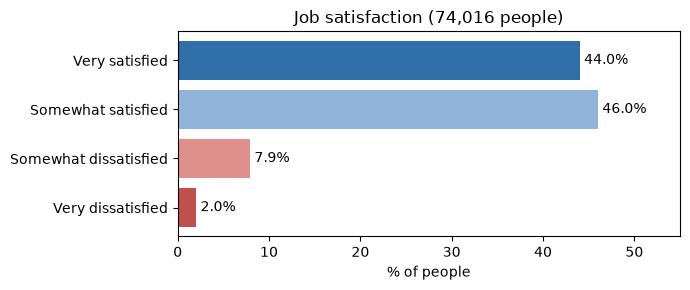

In [9]:
n_dis = df["not_satisfied"].sum()
w_dis = np.average(df["not_satisfied"], weights=df["WTSURVY"])
print(f"Not satisfied (answers 3 or 4): {n_dis:,} of {len(df):,} = {n_dis / len(df):.1%} (weighted: {w_dis:.1%})")
print(f"Ratio: about {(len(df) - n_dis) / n_dis:.1f} satisfied people for every 1 not satisfied")

fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(table["Answer"][::-1], table["% of people"][::-1], color=["#c0504d", "#e0908c", "#8fb3d9", "#2f6ea8"])
for y, v in enumerate(table["% of people"][::-1]):
    ax.text(v + 0.5, y, f"{v}%", va="center")
ax.set_xlabel("% of people")
ax.set_title("Job satisfaction (74,016 people)")
ax.set_xlim(0, 55)
plt.tight_layout()
plt.show()

**Observation:**
- **The classes are very imbalanced.** Only **9.9%** of people (7,361) are not satisfied, about **1 for every 9** satisfied people. Weighted, the rate is 10.2%, so the survey design changes it very little.
- This is why the team uses AUC and class weights instead of plain accuracy: a model that always says "satisfied" would be 90% accurate but useless.
- **"Very satisfied" is 44.0%.** A target of "very satisfied vs. the rest" would be much more balanced (44/56), an option the team has discussed.

## 5. Gender breakdown

NSCG records sex as female or male (`SEX_2023`). The table shows how many people are in each group and how often each group is dissatisfied.

In [10]:
def breakdown(col, labels=None, data=df):
    """People, % of sample, weighted %, and dissatisfied rate for each category of one column."""
    g = data.groupby(col)
    out = pd.DataFrame({
        "People": g.size(),
        "% of people": (g.size() / len(data) * 100).round(1),
        "% weighted": (g["WTSURVY"].sum() / data["WTSURVY"].sum() * 100).round(1),
        "Dissatisfied rate %": (g["not_satisfied"].mean() * 100).round(1),
        "Dissatisfied rate % (weighted)": (g.apply(lambda x: np.average(x["not_satisfied"], weights=x["WTSURVY"]),
                                                   include_groups=False) * 100).round(1),
    })
    if labels:
        out.index = out.index.map(lambda k: labels.get(k, k))
    out.index.name = col
    return out

breakdown("SEX_2023", LABELS["SEX_2023"])

,People,% of people,% weighted,Dissatisfied rate %,Dissatisfied rate % (weighted)
SEX_2023,,,,,
Female,34744,46.9,53.8,10.6,10.6
Male,39272,53.1,46.2,9.4,9.7


In [11]:
by_sex = pd.crosstab(df["SEX_2023"].map(LABELS["SEX_2023"]), df["JOBSATIS"].map(LABELS["JOBSATIS"]),
                     normalize="index").mul(100).round(1)
by_sex[[LABELS["JOBSATIS"][k] for k in "1234"]]

JOBSATIS,Very satisfied,Somewhat satisfied,Somewhat dissatisfied,Very dissatisfied
SEX_2023,,,,
Female,42.1,47.2,8.4,2.3
Male,45.7,44.9,7.5,1.8


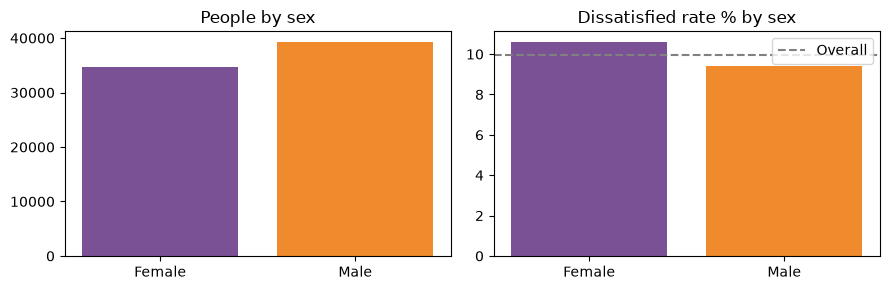

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3))
sex = breakdown("SEX_2023", LABELS["SEX_2023"])
axes[0].bar(sex.index, sex["People"], color=["#7a5195", "#ef8b2c"])
axes[0].set_title("People by sex")
axes[1].bar(sex.index, sex["Dissatisfied rate %"], color=["#7a5195", "#ef8b2c"])
axes[1].axhline(df["not_satisfied"].mean() * 100, color="grey", ls="--", label="Overall")
axes[1].set_title("Dissatisfied rate % by sex")
axes[1].legend()
plt.tight_layout()
plt.show()

**Observation:**
- **The file has more men (53.1%) than women (46.9%)**, but with survey weights it is the opposite: **53.8% women**. So the people in the file are not a mirror of the U.S. college-graduate workforce, and weighted numbers should be used when describing that population.
- **Women are a little more often dissatisfied:** 10.6% vs. 9.4% for men (weighted 10.6% vs. 9.7%). Women are also less often "very satisfied" (42.1% vs. 45.7%).
- The gap is about 1 percentage point, which is small but useful context for the fairness check (Task #4).

## 6. Other key metrics

### 6.1 Numbers: age, salary and weekly hours

In [13]:
num = df[["AGE", "SALARY", "HRSWK"]].describe(percentiles=[0.25, 0.5, 0.75]).T
num = num[["mean", "std", "min", "25%", "50%", "75%", "max"]].round(1)
num.columns = ["Mean", "Std dev", "Min", "25th pct", "Median", "75th pct", "Max"]
num

,Mean,Std dev,Min,25th pct,Median,75th pct,Max
AGE,42.2,13.1,19.0,32.0,39.0,52.0,75.0
SALARY,106957.3,89014.2,0.0,60000.0,90350.0,133000.0,976934.0
HRSWK,40.9,11.2,1.0,40.0,40.0,45.0,96.0


**How to read this:** the **median** is the middle value (half of people are below it). The **25th and 75th percentiles** show the range of the middle half of people. The **standard deviation** shows how spread out the values are.

In [14]:
df.groupby(df["not_satisfied"].map({0: "Satisfied", 1: "Not satisfied"}))[["AGE", "SALARY", "HRSWK"]].median().rename(
    columns={"AGE": "Median age", "SALARY": "Median salary", "HRSWK": "Median weekly hours"})

,Median age,Median salary,Median weekly hours
not_satisfied,,,
Not satisfied,36.0,72000.0,40.0
Satisfied,40.0,93500.0,40.0


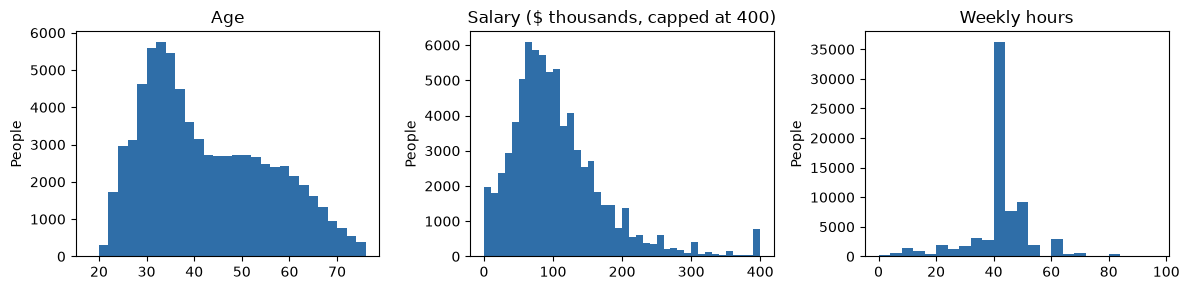

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3))
axes[0].hist(df["AGE"], bins=range(18, 78, 2), color="#2f6ea8")
axes[0].set_title("Age")
axes[1].hist(df["SALARY"].clip(upper=400_000) / 1000, bins=40, color="#2f6ea8")
axes[1].set_title("Salary ($ thousands, capped at 400)")
axes[2].hist(df["HRSWK"], bins=range(0, 100, 4), color="#2f6ea8")
axes[2].set_title("Weekly hours")
for ax in axes:
    ax.set_ylabel("People")
plt.tight_layout()
plt.show()

**Observation:**
- The typical person is **39 years old**, earns **$90,350**, and works **40 hours** a week (medians).
- **Not satisfied people are younger and paid less:** median age 36 vs. 40, and median salary $72,000 vs. $93,500. Median hours are the same (40).
- Salary has a **long right tail**: a few people earn far more than most, which is why models use the log of salary.

### 6.2 Categories: degree, job-degree relatedness, supervising, employer and work activity

In [16]:
for col in ["DGRDG", "OCEDRLP", "SUPWK", "EMSECSM", "EMSIZE"]:
    display(breakdown(col, LABELS[col]))

,People,% of people,% weighted,Dissatisfied rate %,Dissatisfied rate % (weighted)
DGRDG,,,,,
Bachelor's,33834,45.7,61.1,10.7,10.6
Master's,27802,37.6,27.9,9.7,9.9
Doctorate,8687,11.7,4.4,8.5,8.7
Professional,3693,5.0,6.6,8.2,8.4


,People,% of people,% weighted,Dissatisfied rate %,Dissatisfied rate % (weighted)
OCEDRLP,,,,,
Closely related,45315,61.2,53.4,7.7,7.7
Somewhat related,18564,25.1,27.3,11.2,11.3
Not related,10137,13.7,19.4,17.7,15.5


,People,% of people,% weighted,Dissatisfied rate %,Dissatisfied rate % (weighted)
SUPWK,,,,,
Does not supervise,43431,58.7,58.2,11.0,11.3
Supervises others,30585,41.3,41.8,8.4,8.6


,People,% of people,% weighted,Dissatisfied rate %,Dissatisfied rate % (weighted)
EMSECSM,,,,,
Educational institution,14705,19.9,19.4,10.4,10.9
Government,9193,12.4,11.1,8.8,9.9
Business/industry,50118,67.7,69.5,10.0,10.0


,People,% of people,% weighted,Dissatisfied rate %,Dissatisfied rate % (weighted)
EMSIZE,,,,,
10 or fewer,7500,10.1,14.0,8.0,7.7
11-24,3040,4.1,5.3,11.7,10.5
25-99,6263,8.5,9.8,11.1,10.7
100-499,10430,14.1,15.3,10.7,10.8
500-999,5370,7.3,7.1,11.0,10.3
"1,000-4,999",11246,15.2,14.8,10.1,10.7
"5,000-24,999",12708,17.2,14.2,9.4,10.6
"25,000+",17459,23.6,19.5,9.5,10.6


In [17]:
breakdown("WAPRI", LABELS["WAPRI"]).sort_values("People", ascending=False)

,People,% of people,% weighted,Dissatisfied rate %,Dissatisfied rate % (weighted)
WAPRI,,,,,
Managing or supervising,14200,19.2,19.6,8.6,9.3
Professional services,13106,17.7,20.1,9.0,8.8
Teaching,7717,10.4,12.5,10.8,10.6
Applied research,5719,7.7,3.3,9.6,10.3
"Sales, purchasing, marketing",5014,6.8,11.6,14.2,13.3
Design,4816,6.5,3.0,7.9,9.6
"Computer applications, programming",4420,6.0,3.6,8.5,8.9
Development,3988,5.4,3.0,8.8,9.3
"Accounting, finance, contracts",3413,4.6,8.0,10.0,7.4


**Observation:**
- **Job-degree relatedness (`OCEDRLP`) shows the biggest difference.** Dissatisfaction is 7.7% when the job is closely related to the degree, but **17.7%** when it is not related, more than double.
- **Supervisors are less often dissatisfied** (8.4% vs. 11.0%).
- **Higher degrees go with slightly lower dissatisfaction**: 10.7% for bachelor's down to 8.2% for professional degrees.
- **Employer sector and size matter little.** Rates stay between 8.0% and 11.7%, and weighted rates are almost flat (7.7% to 10.9%).
- **Work activity:** people whose main work is sales (14.2%), "other" activities (14.3%) or production (12.8%) are dissatisfied most often. Design (7.9%) is lowest.
- **The file over-represents advanced degrees.** Bachelor's holders are 45.7% of people but 61.1% weighted. Doctorates are 11.7% but only 4.4% weighted.

## 7. Occupations and O*NET matching quality

In [18]:
per_occ = df.groupby("N3OCPR").size()
print(f"{per_occ.size} occupations | people per occupation: min {per_occ.min()}, "
      f"median {per_occ.median():.0f}, max {per_occ.max():,}")
print(f"Occupations with fewer than 100 people: {(per_occ < 100).sum()}")

occ = df.groupby("NSCG_OCC_TITLE").agg(People=("OBSNUM", "size"), dis=("not_satisfied", "mean"))
occ["Dissatisfied rate %"] = (occ.pop("dis") * 100).round(1)
occ.sort_values("People", ascending=False).head(10)

123 occupations | people per occupation: min 12, median 369, max 4,048
Occupations with fewer than 100 people: 16


,People,Dissatisfied rate %
NSCG_OCC_TITLE,,
"Registered nurses, pharmacists, dieticians, therapists, physician assistants, nurse practitioners",4048,8.8
"Top-executives (e.g., chief executives, general and operations managers, legislators)",3673,5.2
"Other management related occupations (e.g., buyers and purchasing agents, claims adjusters, compliance officers, logisticians, management analysts, marketing specialists)",3381,9.8
Other mid-level managers,2184,7.7
Mechanical engineers,2106,8.4
"Financial specialists (e.g., accountants, auditors)",2038,10.9
Other office and administrative support workers,1955,17.7
Electrical and electronics engineers,1916,7.4
Other health occupations,1754,11.5


In [19]:
big = occ[occ["People"] >= 100].sort_values("Dissatisfied rate %")
print(f"Among the {len(big)} occupations with at least 100 people:")
display(pd.concat({"Lowest dissatisfied rate": big.head(5), "Highest dissatisfied rate": big.tail(5)}))

Among the 107 occupations with at least 100 people:


People  Dissatisfied rate %
                          NSCG_OCC_TITLE                                                                 
Lowest dissatisfied rate  Clergy and other religious workers                     298                  4.4
                          Actuaries                                              176                  4.5
                          Statisticians                                          322                  4.7
                          Psychologists - Health services (e.g., clinical...     546                  4.9
                          Top-executives (e.g., chief executives, general...    3673                  5.2
Highest dissatisfied rate Other office and administrative support workers       1955                 17.7
                          Other service occupations, except health (e.g.,...     739                 17.7
                          Secretaries and administrative assistants, and ...     574                 18.8
                          Retail sales workers (e.g., furnishings, clothi...     594                 22.1
                          Food preparation and service occupations (e.g.,...     346                 24.0

**Matching quality:** Some NSCG occupations did not have an exact O*NET match, so the team used a similar or broader occupation instead. This is called a **proxy** match. `MAPPING_COVERAGE` shows whether O*NET ratings were available for all (`full`) or only some (`partial`) of the jobs inside an occupation group.

In [20]:
display(breakdown("MAPPING_IS_PROXY", {"False": "Exact or reviewed match", "True": "Proxy match"}))
display(breakdown("MAPPING_COVERAGE"))
breakdown("MAPPING_TYPE").sort_values("People", ascending=False)

,People,% of people,% weighted,Dissatisfied rate %,Dissatisfied rate % (weighted)
MAPPING_IS_PROXY,,,,,
Exact or reviewed match,50767,68.6,66.9,9.9,10.5
Proxy match,23249,31.4,33.1,10.1,9.6


,People,% of people,% weighted,Dissatisfied rate %,Dissatisfied rate % (weighted)
MAPPING_COVERAGE,,,,,
full,39084,52.8,40.5,9.0,10.0
partial,34932,47.2,59.5,11.0,10.3


,People,% of people,% weighted,Dissatisfied rate %,Dissatisfied rate % (weighted)
MAPPING_TYPE,,,,,
group_mean_partial,33658,45.5,58.8,11.0,10.3
single_SOC,18859,25.5,12.3,8.8,9.0
group_mean_complete,17170,23.2,26.0,9.3,10.7
single_SOC_broader_profile,3010,4.1,2.3,9.0,8.2
single_available_proxy,1274,1.7,0.6,9.7,9.9
residual_single_proxy,45,0.1,0.0,6.7,5.1


In [21]:
wv = [c for c in df.columns if c.startswith("ONET_WV_") and c[8:9].islower()]
print(f"Distinct O*NET profiles: {df['ONET_PROFILE_ID'].nunique()} | rating scale: {df['ONET_WV_SCALE'].iloc[0]} "
      f"| version: {df['ONET_WV_VERSION'].iloc[0]}")
prof = df.drop_duplicates("ONET_PROFILE_ID")[wv]
prof.columns = [c.replace("ONET_WV_", "") for c in wv]
prof.describe().T[["mean", "std", "min", "max"]].round(2)

Distinct O*NET profiles: 123 | rating scale: EX | version: 30.2


,mean,std,min,max
achievement,5.06,0.88,2.53,6.17
working_conditions,4.95,0.82,2.46,6.50
recognition,4.59,0.94,2.26,6.33
relationships,4.58,1.13,2.00,7.00
support,4.11,0.86,2.33,5.67
independence,5.06,0.77,3.00,6.11


O*NET scores describe the **occupation**, not the person, so everyone in the same occupation has the same six values. The table above summarizes one row per occupation profile (1 = low, 7 = high).

**Observation:**
- **Occupation sizes vary a lot:** from 12 to 4,048 people. **16 occupations have fewer than 100 people**, so their rates are less reliable.
- **Dissatisfaction differs a lot by occupation:** from **4.4%** (clergy) to **24.0%** (food preparation and service), among occupations with at least 100 people.
- **31.4% of people have a proxy match**, but their dissatisfied rate (10.1%) is almost the same as for exact or reviewed matches (9.9%).
- **47.2% of people have partial O*NET coverage**, meaning O*NET ratings were available for only some jobs in their occupation group.
- There are **123 O*NET profiles, one per occupation**. The six work values all vary across occupations, and "relationships" has the widest range (2.0 to 7.0).

## 8. Personal work values and job-aspect satisfaction

In [22]:
imp = pd.DataFrame({
    ASPECTS[a]: df[f"FAC{a}"].map(IMPORTANCE).value_counts(normalize=True).mul(100) for a in ASPECTS
}).T[list(IMPORTANCE.values())].round(1).sort_values("Very important", ascending=False)
imp

,Very important,Somewhat important,Somewhat unimportant,Not important at all
Salary,76.1,22.4,1.0,0.5
Benefits,74.8,21.2,2.4,1.6
Job security,71.6,24.8,2.4,1.2
Location,64.2,31.9,3.1,0.8
Independence,63.5,33.2,2.8,0.5
Intellectual challenge,57.0,37.7,4.4,0.9
Contribution to society,51.3,38.3,8.2,2.2
Advancement,47.3,40.8,8.8,3.1
Responsibility,41.5,49.2,7.9,1.4


These `FAC*` columns show what each person says matters to them in a job. In the November models, adding them gave the largest improvement.

In [23]:
sat = pd.DataFrame({
    ASPECTS[a]: {"% dissatisfied with this aspect": round(df[f"SAT{a}"].isin(["3", "4"]).mean() * 100, 1),
                 "Overall dissatisfied rate % among them": round(df.loc[df[f"SAT{a}"].isin(["3", "4"]), "not_satisfied"].mean() * 100, 1)}
    for a in ASPECTS
}).T.sort_values("% dissatisfied with this aspect", ascending=False)
sat

,% dissatisfied with this aspect,Overall dissatisfied rate % among them
Advancement,28.7,27.0
Salary,22.2,28.8
Benefits,18.4,24.4
Intellectual challenge,14.3,39.1
Job security,11.6,31.6
Contribution to society,11.6,36.7
Responsibility,10.4,45.9
Location,10.0,26.6
Independence,7.4,46.2


**Warning (data leakage):** `SAT*` columns ask how satisfied a person is with each part of their job. That is almost the same question as our target, so using them as model inputs would give the model part of the answer. They are shown here only to describe the data.

**Observation:**
- **Salary (76.1%), benefits (74.8%) and job security (71.6%)** are rated "very important" most often. **Responsibility (41.5%)** is the least.
- People are most often dissatisfied with **advancement (28.7%)** and **salary (22.2%)**.
- **The leakage risk is clear in the data.** Among people dissatisfied with their independence, 46.2% are dissatisfied with their job overall, compared with 9.9% of everyone.

## 9. Who was left out? Comparing with the 79,800-person cleaned file

The cleaned file from the October EDA (`nscg2023_clean.csv`) has 79,800 employed people. The integrated file keeps 74,016 of them. The rest were left out because their occupation could not be matched to O*NET with confidence.

The cleaned file has no person ID, so we cannot match people one by one. Instead, we compare **totals**: left-out count = cleaned-file count minus integrated-file count, for each group.

In [24]:
clean = pd.read_csv(CLEAN, dtype={"SEX_2023": str, "N3OCPR": str})
clean["not_satisfied"] = (clean["satisfied"] == 0).astype(int)

def compare(col_clean, col_int, labels=None):
    a = clean.groupby(col_clean).agg(people=("not_satisfied", "size"), dis=("not_satisfied", "sum"))
    b = df.groupby(col_int).agg(people=("not_satisfied", "size"), dis=("not_satisfied", "sum"))
    a.index, b.index = a.index.astype(str), b.index.astype(str)
    out = a.sub(b, fill_value=0)
    if (out < 0).any().any():
        raise ValueError("Integrated file has more people than the cleaned file in some group")
    res = pd.DataFrame({
        "Left out (people)": out["people"].astype(int),
        "Left out: dissatisfied rate %": (out["dis"] / out["people"] * 100).round(1),
        "Kept: dissatisfied rate %": (b["dis"] / b["people"] * 100).round(1),
    })
    if labels:
        res.index = res.index.map(lambda k: labels.get(k, k))
    return res

left = len(clean) - len(df)
left_dis = (clean["not_satisfied"].sum() - df["not_satisfied"].sum()) / left
print(f"Cleaned file: {len(clean):,} | integrated file: {len(df):,} | left out: {left:,} ({left / len(clean):.1%})")
print(f"Dissatisfied rate: left out {left_dis:.1%} vs kept {df['not_satisfied'].mean():.1%}")
compare("SEX_2023", "SEX_2023", LABELS["SEX_2023"])

Cleaned file: 79,800 | integrated file: 74,016 | left out: 5,784 (7.2%)
Dissatisfied rate: left out 9.0% vs kept 9.9%


,Left out (people),Left out: dissatisfied rate %,Kept: dissatisfied rate %
SEX_2023,,,
Female,1719,8.2,10.6
Male,4065,9.3,9.4


In [25]:
left_occ = compare("N3OCPR", "N3OCPR")
left_occ = left_occ[left_occ["Left out (people)"] > 0]
names = clean.drop_duplicates("N3OCPR").set_index("N3OCPR")["occupation"]
left_occ.insert(0, "Occupation", left_occ.index.map(names))
left_occ.sort_values("Left out (people)", ascending=False).drop(columns="Kept: dissatisfied rate %")

,Occupation,Left out (people),Left out: dissatisfied rate %
N3OCPR,,,
110590,Software developers – applications and systems...,4069,8.5
220270,Other life scientists,509,8.8
121770,Data scientists,411,9.0
785000,Other occupations (not elsewhere classified),377,14.6
732570,Teachers: Other precollegiate area,171,7.6
570980,Sales engineers,91,6.6
121760,Other mathematical scientists,79,6.3
780310,"Bookkeeping, accounting, and auditing clerks",77,19.5


The "Left out" numbers depend on the cleaned file and the integrated file covering the same 79,800 people. Both come from the same NSCG release with the same filter (employed people who answered the satisfaction question), and no group has more people in the integrated file than in the cleaned file.

**Observation:**
- **5,784 people (7.2%) were left out.** Their dissatisfied rate (9.0%) is close to the kept group's (9.9%).
- **Most left-out people are software developers: 4,069 people, or 70% of everyone left out.** The integration notebook excludes software developers, other life scientists, data scientists and other mathematical scientists because O*NET has no Work Values ratings for them. It excludes other precollegiate teachers and unclassified occupations because the match was uncertain. A supervisor rule removed some sales engineers and bookkeeping clerks.
- **The left-out group is mostly men** (4,065 men vs. 1,719 women).
- **What this means:** our models say nothing about software developers, data scientists and the other excluded jobs, so we should not apply results to them.